# Session 11 lecture: Operations: service performance

<p class="lead">
"How many deliveries arrive on time?" sounds like the easiest question in operations. It is easy to get wrong: shipments that have not arrived yet quietly drop out, early deliveries for next month sneak in, and a carrier's bad week hides inside a warehouse average. This lecture builds an on-time rate that a manager can trust, then looks at delivery times, the backlog of late work and fair comparisons between carriers and warehouses.
</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aayush181509/AnalyticsLecture/blob/main/notebooks/11_operations_service_lecture.ipynb)

Open this notebook in Google Colab with the button above, then run each cell from top to bottom with **Shift + Enter**. Save your own copy with **File → Save a copy in Drive**.

---

## Recap quiz

Before we start, answer these questions on the [Session 10 lecture](10_finance_budget_lecture.md). Write short answers; we discuss them together.

1. A cost line had a budget of 10,000 and actual spending of 9,000. What is the variance in currency units? Is it favourable or unfavourable?
2. Why do finance teams label variances "favourable" or "unfavourable" instead of relying only on the plus or minus sign?
3. The budget table has one row per department per month; the actuals table has one row per invoice. In what order would you aggregate and join them, and why?
4. After a join, the total budget is three times what finance expected. What is the most likely cause, and how would you check it?
5. Line X is 40% over a small budget; line Y is 3% over a very large one. Which do you look at first, and what number helps you decide?

---

## What you will be able to explain

1. How **event dates** and a **cutoff** turn a stream of shipments into a snapshot, and what each **status** means at that moment.
2. Why the **grain** is the shipment, not the order, when one order can be split.
3. Which shipments belong in the **due population**, and why **not-yet-due** and **unknown-promise** shipments stay out of the on-time rate.
4. Why an on-time rate built on **delivered shipments only** overstates service (survivorship).
5. How to describe **lead time** for completed shipments: distribution, mean versus median, percentiles and tails, box plots.
6. How to measure the **backlog**: days past due and how old the late work is.
7. How to compare carriers and warehouses **fairly**: ratios of counts, visible volumes, carrier **mix**, and honest uncertainty for small groups.

This lecture reuses ideas from earlier sessions: weighted rates and Simpson's paradox ([Session 5](05_metrics_and_kpis_lecture.md)), distributions and percentiles ([Session 4](04_descriptive_statistics_lecture.md)), trends ([Session 7](07_trends_and_growth_lecture.md)) and intervals for rates ([Session 9](09_sampling_and_experiments_lecture.md)). In the **Lab** you build the same measures yourself, fix three broken dashboards and recommend one process to investigate.

> **How to use the questions in this notebook**
>
> **Predict, then reveal** boxes ask you to guess before running the next cell. Write your guess down first. **Check your understanding** boxes are short questions to answer in your own words.

Run the two setup cells first. The first downloads the course's **synthetic** shipment data and checks it. The second sets up the charts.

In [1]:
# Operations data setup (synthetic). Run this cell first.
# Downloads the course's synthetic shipment data from GitHub and checks it is the exact version this course uses.
import hashlib
import io
import os
import urllib.request

import pandas as pd

OPERATIONS_URL = "https://raw.githubusercontent.com/Aayush181509/AnalyticsLecture/main/data/synthetic/operations-v1/"
OPERATIONS_SHA256 = {"shipments.csv": "7b5c0860beb2a16ba4f84a3dd0b5bdf9d88e968b720c6541f1dcb7d688c75687"}
OPERATIONS_DIR = os.environ.get("COURSE_OPERATIONS_DIR", "")
CUTOFF = pd.Timestamp("2025-12-31")


def load_shipments():
    """Load operations-v1 shipments: one row per shipment, known at the end of 2025-12-31."""
    if OPERATIONS_DIR:
        with open(os.path.join(OPERATIONS_DIR, "shipments.csv"), "rb") as f:
            data = f.read()
    else:
        data = urllib.request.urlopen(OPERATIONS_URL + "shipments.csv").read()
    if hashlib.sha256(data).hexdigest() != OPERATIONS_SHA256["shipments.csv"]:
        print("WARNING: this file differs from the course version. Ask your facilitator.")
    return pd.read_csv(io.BytesIO(data), parse_dates=["dispatch_date", "promised_date", "delivered_date"])


print("Operations setup complete.")

Operations setup complete.


In [2]:
import matplotlib.pyplot as plt
import numpy as np

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a"]),
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
print("Plot style ready.")

Plot style ready.


---

## Part 1: The decision

> *Operations manager: "Customers are complaining about late deliveries, and December felt terrible. I can afford one improvement project next quarter. Tell me which carrier or warehouse process to investigate first, and how sure you are."*

The manager is not asking for a pretty chart. They need to **choose one thing to investigate**, so the analysis must:

| The manager needs | So we measure |
|---|---|
| How reliable is delivery overall? | The on-time rate, with the right numerator and denominator |
| Where is reliability worst? | On-time rate by carrier and warehouse, with volumes |
| How bad is the late work right now? | The backlog of overdue shipments and how old it is |
| How long do deliveries take? | Lead-time distribution, not only its average |
| Is a difference real or just mix or noise? | Mix-aware comparisons and intervals for small groups |

> **About the data**
>
> **`shipments.csv`** (operations-v1) is **synthetic** teaching data generated by the course: a fictional retailer's outbound shipments dispatched in 2025, with three fictional warehouses and three fictional carriers. It is a **snapshot taken at the end of 31 December 2025**, the **cutoff**. Dates are calendar days.

---

## Part 2: Event dates, a cutoff and statuses

Each shipment has up to three **event dates**:

| Date | Meaning | Can it be blank? |
|---|---|---|
| `dispatch_date` | The day it left the warehouse | No: every row was dispatched by the cutoff |
| `promised_date` | The day delivery was promised to the customer | Yes, for a few rows: the promise was not recorded (a data-quality problem) |
| `delivered_date` | The day it was delivered | Yes: **not delivered by the cutoff**, or canceled |

A blank `delivered_date` does **not** mean "never". It means "**not yet, as far as we knew on 31 December**". Some of those shipments will arrive in January. Data like this, where the outcome is unknown at the snapshot, is called **censored**: we only know the delivery takes *at least* this long.

In [3]:
shipments = load_shipments()
print("Rows:", len(shipments), "| columns:", list(shipments.columns))
shipments[["shipment_id", "order_id", "carrier", "dispatch_date", "promised_date", "delivered_date", "status"]].head()

Rows: 5893 | columns: ['shipment_id', 'order_id', 'warehouse_id', 'warehouse', 'carrier_id', 'carrier', 'service', 'dispatch_date', 'promised_date', 'delivered_date', 'status']


,shipment_id,order_id,carrier,dispatch_date,promised_date,delivered_date,status
0,SHP-00001,ORD-00001,ParcelOne,2025-01-01,2025-01-03,2025-01-03,delivered
1,SHP-00002,ORD-00002,SwiftRoute,2025-01-01,2025-01-06,2025-01-04,delivered
2,SHP-00003,ORD-00003,ParcelOne,2025-01-01,2025-01-06,2025-01-05,delivered
3,SHP-00004,ORD-00004,SwiftRoute,2025-01-01,2025-01-06,2025-01-18,delivered
4,SHP-00005,ORD-00005,Regional Express,2025-01-01,2025-01-06,2025-01-04,delivered


First check what the **status** column says, and whether it agrees with the dates.

In [4]:
status_check = pd.crosstab(
    shipments["status"],
    [shipments["delivered_date"].notna().map({True: "delivered date known", False: "delivered date blank"})],
    margins=True, margins_name="All",
)
status_check

delivered_date,delivered date blank,delivered date known,All
status,,,
canceled,40,0,40
delivered,0,5603,5603
in_transit,250,0,250
All,290,5603,5893


In the table above, every `delivered` shipment has a delivery date and every `in_transit` or `canceled` shipment has none. That agreement is worth checking every time: if they disagreed, you would have to decide which one to trust before measuring anything.

Next, **date order**. Nothing can be delivered before it is dispatched, and nothing in a 31 December snapshot can be delivered after 31 December.

In [5]:
checks = {
    "delivered before dispatch": (shipments["delivered_date"] < shipments["dispatch_date"]).sum(),
    "promised before dispatch": (shipments["promised_date"] < shipments["dispatch_date"]).sum(),
    "dispatched after the cutoff": (shipments["dispatch_date"] > CUTOFF).sum(),
    "delivered after the cutoff": (shipments["delivered_date"] > CUTOFF).sum(),
    "promised after the cutoff (not yet due)": (shipments["promised_date"] > CUTOFF).sum(),
    "promise date missing": shipments["promised_date"].isna().sum(),
}
pd.Series(checks, name="rows")

delivered before dispatch                   0
promised before dispatch                    0
dispatched after the cutoff                 0
delivered after the cutoff                  0
promised after the cutoff (not yet due)    99
promise date missing                       12
Name: rows, dtype: int64

Read the counts above. The first four are impossible events and should be zero. The last two are **not errors**: some promises fall in January (the customer was told "you will have it on 2 January"), and a few promise dates were never recorded. Both groups need special treatment in Part 4.

> **Check your understanding 1**
>
> A shipment has status `in_transit` and was promised for 28 December. Is it late? Will it always be late? What would you need to know to answer the second question?

---

## Part 3: The grain is the shipment

A customer **order** can be **split** into more than one **shipment** (for example, one item ships from another warehouse). The carrier delivers shipments, not orders.

In [6]:
print("Unique shipment_id:", shipments["shipment_id"].is_unique)
print("Unique order_id:   ", shipments["order_id"].is_unique)
print()
print("Shipments per order:")
shipments.groupby("order_id").size().value_counts().sort_index().rename_axis("shipments in the order").rename("orders")

Unique shipment_id: True
Unique order_id:    False

Shipments per order:


shipments in the order
1    4507
2     693
Name: orders, dtype: int64

So `shipment_id` is the **key** (one row each) and `order_id` repeats. One split order can have one part on time and one part late. If you count **orders**, you have to invent a rule ("an order is on time if its first part is?"), and the denominator no longer matches the carrier's work. **Count shipments for service measures.** You will see what goes wrong when someone counts orders in the lab.

---

## Part 4: A tiny hand fixture

Before touching 5,000 rows, we work through eight made-up shipments by hand. Each one is a different situation you will meet in real data.

In [7]:
fixture = pd.DataFrame({
    "shipment_id": ["A", "B", "C", "D", "E", "F", "G", "H"],
    "situation": ["on time", "late", "overdue, still pending", "due today, still pending",
                  "not yet due, delivered early", "unknown promise", "canceled", "delivered on the promise day"],
    "status": ["delivered", "delivered", "in_transit", "in_transit", "delivered", "delivered", "canceled", "delivered"],
    "dispatch_date": ["2025-12-05", "2025-12-05", "2025-12-15", "2025-12-26", "2025-12-28", "2025-12-08", "2025-12-22", "2025-12-26"],
    "promised_date": ["2025-12-10", "2025-12-10", "2025-12-20", "2025-12-31", "2026-01-02", None, "2025-12-27", "2025-12-31"],
    "delivered_date": ["2025-12-09", "2025-12-14", None, None, "2025-12-30", "2025-12-12", None, "2025-12-31"],
})
for col in ["dispatch_date", "promised_date", "delivered_date"]:
    fixture[col] = pd.to_datetime(fixture[col])
fixture

,shipment_id,situation,status,dispatch_date,promised_date,delivered_date
0,A,on time,delivered,2025-12-05,2025-12-10,2025-12-09
1,B,late,delivered,2025-12-05,2025-12-10,2025-12-14
2,C,"overdue, still pending",in_transit,2025-12-15,2025-12-20,NaT
3,D,"due today, still pending",in_transit,2025-12-26,2025-12-31,NaT
4,E,"not yet due, delivered early",delivered,2025-12-28,2026-01-02,2025-12-30
5,F,unknown promise,delivered,2025-12-08,NaT,2025-12-12
6,G,canceled,canceled,2025-12-22,2025-12-27,NaT
7,H,delivered on the promise day,delivered,2025-12-26,2025-12-31,2025-12-31


> **Predict, then reveal**
>
> The cutoff is the end of 31 December 2025. For each row, decide: is it in the **due population** (promised on or before the cutoff, not canceled)? If it is, was it **on time** (delivered on or before the promise)? Then write down the **numerator** (on-time due shipments) and the **denominator** (all due shipments) before you run the next cell.

The rules, from the data's metric contract:

| Situation | In the on-time denominator? | Why |
|---|---|---|
| Canceled | No | Nothing to deliver |
| Promise unknown | No, but **count it and say so** | We cannot judge it; hiding the count hides a data problem |
| Promised **after** the cutoff | No ("not yet due"), even if already delivered | Its deadline has not arrived; it is still workload |
| Promised on or before the cutoff | **Yes** ("due"), delivered **or not** | The deadline has passed; an undelivered one is a failure |
| Due and delivered on or before the promise | Yes, and in the **numerator** | On time |

The function below applies these rules. We reuse it on the real data.

In [8]:
def add_service_columns(df, cutoff=CUTOFF):
    """Label each shipment's population at the cutoff and add on-time, pending and lead-time columns."""
    out = df.copy()
    out["population"] = np.select(
        [out["status"] == "canceled", out["promised_date"].isna(), out["promised_date"] > cutoff],
        ["canceled", "unknown promise", "not yet due"],
        default="due",
    )
    delivered = out["delivered_date"].notna()
    out["on_time"] = delivered & (out["delivered_date"] <= out["promised_date"])
    out["pending"] = ~delivered & (out["status"] != "canceled")
    # Days past due: only for due shipments still pending; at least 0 (due today = 0).
    overdue = (out["population"] == "due") & out["pending"]
    out["days_past_due"] = (cutoff - out["promised_date"]).dt.days.clip(lower=0).where(overdue)
    # Lead time: completed (delivered) shipments only; blank otherwise.
    out["lead_days"] = (out["delivered_date"] - out["dispatch_date"]).dt.days
    return out


fx = add_service_columns(fixture)
fx[["shipment_id", "situation", "population", "on_time", "pending", "days_past_due", "lead_days"]]

,shipment_id,situation,population,on_time,pending,days_past_due,lead_days
0,A,on time,due,True,False,NaN,4.00
1,B,late,due,False,False,NaN,9.00
2,C,"overdue, still pending",due,False,True,11.00,NaN
3,D,"due today, still pending",due,False,True,0.00,NaN
4,E,"not yet due, delivered early",not yet due,True,False,NaN,2.00
5,F,unknown promise,unknown promise,False,False,NaN,4.00
6,G,canceled,canceled,False,False,NaN,NaN
7,H,delivered on the promise day,due,True,False,NaN,5.00


In [9]:
due_fx = fx[fx["population"] == "due"]
print("Due shipments (denominator):     ", len(due_fx), "->", list(due_fx["shipment_id"]))
print("On time among due (numerator):   ", due_fx["on_time"].sum(), "->", list(due_fx.loc[due_fx["on_time"], "shipment_id"]))
print(f"On-time rate:                     {due_fx['on_time'].mean():.0%}")
print()
delivered_fx = due_fx[due_fx["delivered_date"].notna()]
print(f"'Delivered only' rate (wrong):    {delivered_fx['on_time'].mean():.0%}  from {len(delivered_fx)} shipments")
print("Excluded and reported:", fx.loc[fx["population"] != "due", "population"].value_counts().to_dict())

Due shipments (denominator):      5 -> ['A', 'B', 'C', 'D', 'H']
On time among due (numerator):    2 -> ['A', 'H']
On-time rate:                     40%

'Delivered only' rate (wrong):    67%  from 3 shipments
Excluded and reported: {'not yet due': 1, 'unknown promise': 1, 'canceled': 1}


Compare the output with your prediction. Three details trip people up:

1. **C and D** have not arrived, so they are in the **denominator** and not in the numerator. D was due today and is still pending: it is a failure **at the snapshot**, with 0 days past due.
2. **E** arrived early, but its deadline is in January. Counting it now would let next month's easy wins flatter this month's score.
3. **H** was delivered **on** the promise day. "On or before" means it is on time; check the boundary every time you write a comparison (`<=`, not `<`).

> **Check your understanding 2**
>
> A colleague says: "Shipment E was delivered early, so leaving it out is unfair to the carrier." What do you reply? When **will** shipment E count?

---

## Part 5: The due population and the on-time rate

Now the real data. First label every shipment and **reconcile** the populations: every shipment must land in exactly one group, and the groups must add back to the total.

In [10]:
s = add_service_columns(shipments)

populations = s["population"].value_counts().reindex(["due", "not yet due", "unknown promise", "canceled"])
display(populations.rename("shipments").to_frame())
print("Groups add up to all shipments:", populations.sum() == len(s))

eligible = s[s["population"] != "canceled"]
print("Eligible (not canceled):", len(eligible), "= due + not yet due + unknown promise:",
      populations[["due", "not yet due", "unknown promise"]].sum() == len(eligible))

,shipments
population,
due,5742
not yet due,99
unknown promise,12
canceled,40


Groups add up to all shipments: True
Eligible (not canceled): 5853 = due + not yet due + unknown promise: True


Inside the due population, some shipments were delivered and some are still pending:

In [11]:
due = s[s["population"] == "due"]

due_breakdown = pd.Series({
    "delivered on time": (due["on_time"]).sum(),
    "delivered late": (due["delivered_date"].notna() & ~due["on_time"]).sum(),
    "still pending (overdue or due today)": due["pending"].sum(),
}, name="due shipments")
display(due_breakdown.to_frame())

on_time_rate = due["on_time"].sum() / len(due)
print(f"On-time rate = {due['on_time'].sum()} on-time due shipments / {len(due)} due shipments = {on_time_rate:.1%}")
print(f"Not counted in the rate: {populations['not yet due']} not yet due, "
      f"{populations['unknown promise']} with an unknown promise date (reported, not hidden).")

,due shipments
delivered on time,4700
delivered late,885
still pending (overdue or due today),157


On-time rate = 4700 on-time due shipments / 5742 due shipments = 81.9%
Not counted in the rate: 99 not yet due, 12 with an unknown promise date (reported, not hidden).


That printed sentence is the format to use with a manager: the rate **and** its numerator and denominator, **and** what was left out and why.

> **Zero denominators**
>
> If a group has no due shipments (a new carrier, a quiet week), its on-time rate is **not available**, never 0% or 100%. pandas gives `NaN` when you divide 0 by 0; show it as "n/a" with the count of 0.

---

## Part 6: Why "delivered only" overstates service

Many dashboards start with a filter `status == "delivered"`, because only delivered rows have a delivery date to compare. That one filter removes every overdue shipment that is still stuck: the **worst** cases disappear.

> **Predict, then reveal**
>
> Will the delivered-only rate be higher or lower than the correct rate? By a lot or a little?

In [12]:
delivered_due = due[due["delivered_date"].notna()]
delivered_only_rate = delivered_due["on_time"].mean()

comparison = pd.DataFrame({
    "on time": [due["on_time"].sum(), delivered_due["on_time"].sum()],
    "denominator": [len(due), len(delivered_due)],
    "on-time rate": [on_time_rate, delivered_only_rate],
}, index=["Correct: all due shipments", "Wrong: delivered only"])
display(comparison.assign(**{"on-time rate": comparison["on-time rate"].map("{:.1%}".format)}))
print(f"Shipments that vanish with the filter: {len(due) - len(delivered_due)} (all of them failures)")

,on time,denominator,on-time rate
Correct: all due shipments,4700,5742,81.9%
Wrong: delivered only,4700,5585,84.2%


Shipments that vanish with the filter: 157 (all of them failures)


The numerator is the same in both rows; only the denominator shrinks. This is **survivorship**: by looking only at shipments that "survived" to delivery, you lose exactly the ones that failed worst. The gap grows when things go badly, because that is when more shipments are stuck. In other words, the wrong method looks best **exactly when the operation is worst**. Part 11 shows this month by month.

> **Check your understanding 3**
>
> A carrier stops delivering entirely for the last week of the year. What happens to its delivered-only on-time rate for that week? What happens to the correct rate?

---

## Part 7: Lead time for completed shipments

The on-time rate is a yes/no measure. **Lead time** (delivered date − dispatch date, in calendar days) shows **how long** deliveries take. It exists only for **completed** shipments, so always say so and give the count.

> **Predict, then reveal**
>
> Lead times cannot be negative, most deliveries take a few days, and a few take weeks. Will the mean be above, below or equal to the median?

,completed,mean,median,p75,p90,p95,max
service,,,,,,,
Express,1200,3.08,2.00,3.00,4.00,12.00,24.00
Standard,4403,4.90,4.00,4.00,6.00,15.00,26.00


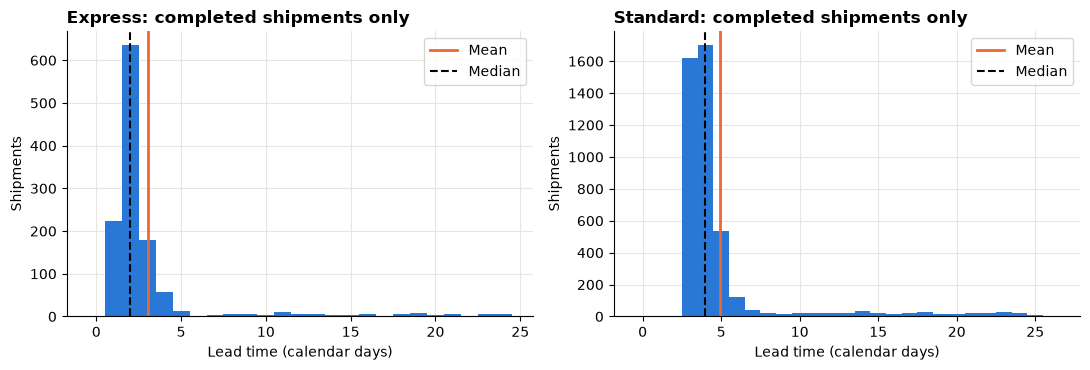

In [13]:
completed = s[s["delivered_date"].notna()]

lead_summary = completed.groupby("service")["lead_days"].agg(
    completed="count", mean="mean", median="median",
    p75=lambda x: x.quantile(0.75), p90=lambda x: x.quantile(0.90), p95=lambda x: x.quantile(0.95), max="max",
)
display(lead_summary)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=False)
for ax, (service, part) in zip(axes, completed.groupby("service")):
    bins = np.arange(0, part["lead_days"].max() + 2) - 0.5
    ax.hist(part["lead_days"], bins=bins)
    ax.axvline(part["lead_days"].mean(), color="#eb6834", linewidth=2, label="Mean")
    ax.axvline(part["lead_days"].median(), color="black", linestyle="--", label="Median")
    ax.set_title(f"{service}: completed shipments only")
    ax.set_xlabel("Lead time (calendar days)")
    ax.set_ylabel("Shipments")
    ax.legend()
fig.tight_layout()
plt.show()

Read the charts and table above:

1. The distributions are **right-skewed**: a tall peak at a few days and a long thin **tail** of slow deliveries.
2. The tail pulls the **mean** above the **median**. The median says "a typical delivery"; the mean is pushed up by the stragglers.
3. **Percentiles** describe the tail directly. "90% of Standard deliveries arrive within *p90* days" is a promise a manager can check against the contract; the mean is not.

Express and Standard have different promises (2 and 5 days), so **never pool them** into one lead-time average: a change in the share of Express would move the average even if no delivery got faster.

### Box plots

A **box plot** shows the same distribution compactly, which is handy for comparing many groups side by side. The box runs from the 25th to the 75th percentile, the line inside is the median, and the dots are unusually slow (or fast) deliveries.

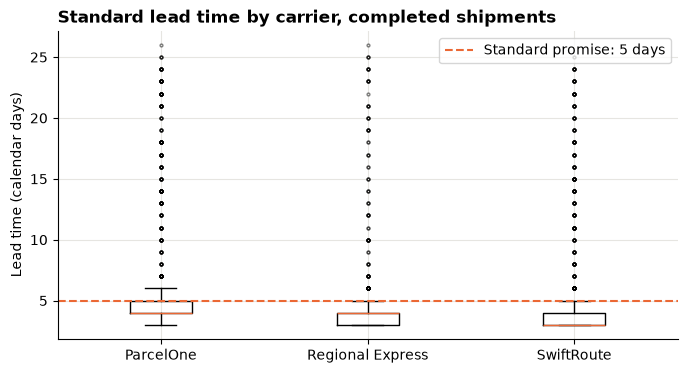

In [14]:
standard = completed[completed["service"] == "Standard"]
carriers = sorted(standard["carrier"].unique())

ax = plt.gca()
ax.boxplot([standard.loc[standard["carrier"] == c, "lead_days"] for c in carriers],
           flierprops={"marker": ".", "markersize": 4, "alpha": 0.5})
ax.set_xticks(range(1, len(carriers) + 1), carriers)
ax.axhline(5, color="#eb6834", linestyle="--", label="Standard promise: 5 days")
ax.set_title("Standard lead time by carrier, completed shipments")
ax.set_ylabel("Lead time (calendar days)")
ax.legend(loc="upper right")
plt.show()

### What completed-only lead time leaves out

Lead time is measured only for shipments that arrived. The shipments still pending at the cutoff are, by definition, the ones that are taking a long time, and they are missing from the chart. So completed-only lead time is **optimistic**, the same survivorship problem as Part 6. The pending shipments are not useless: we know they have taken **at least** this long so far.

In [15]:
pending_due = s[(s["population"] == "due") & s["pending"]]
age_so_far = (CUTOFF - pending_due["dispatch_date"]).dt.days

print(f"Completed shipments in the lead-time chart: {len(completed)}")
print(f"Due shipments still pending, not in the chart: {len(pending_due)}")
print(f"Their time since dispatch so far: median {age_so_far.median():.0f} days, max {age_so_far.max()} days (and counting)")

Completed shipments in the lead-time chart: 5603
Due shipments still pending, not in the chart: 157
Their time since dispatch so far: median 11 days, max 24 days (and counting)


> **Check your understanding 4**
>
> Your report says "median Standard lead time: *x* days (completed shipments)". A manager asks why you added "(completed shipments)". Explain in one sentence, and say which direction the true figure probably lies.

---

## Part 8: The backlog: days past due

The on-time rate looks back. The **backlog** looks at today: how many due shipments are still pending, and **how late** they already are.

*Days past due = cutoff − promised date*, for due shipments still pending, never below 0. A shipment promised for the cutoff day and still pending has 0 days past due, but it is still a failure at the snapshot.

age_band,0 (due today),1–3,4–7,8–14,15+,All
carrier,,,,,,
ParcelOne,6,30,37,35,21,129
Regional Express,2,3,3,0,0,8
SwiftRoute,5,6,4,3,2,20
All,13,39,44,38,23,157


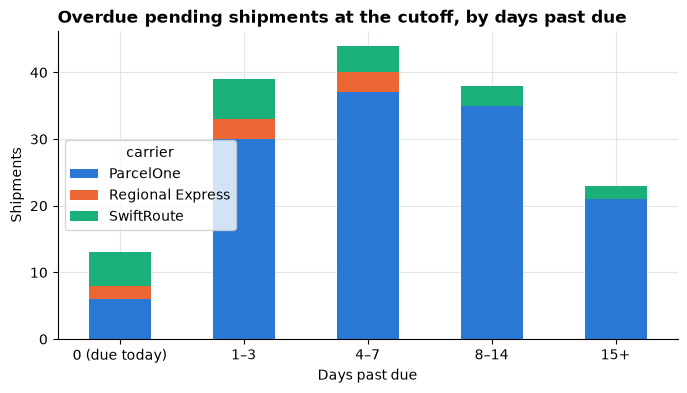

In [16]:
bucket_edges = [-1, 0, 3, 7, 14, 10_000]
bucket_names = ["0 (due today)", "1–3", "4–7", "8–14", "15+"]
pending_due = pending_due.assign(age_band=pd.cut(pending_due["days_past_due"], bucket_edges, labels=bucket_names))

backlog = pd.crosstab(pending_due["carrier"], pending_due["age_band"], margins=True, margins_name="All")
display(backlog)

ax = backlog.drop(index="All", columns="All").T.plot(kind="bar", stacked=True, rot=0)
ax.set_title("Overdue pending shipments at the cutoff, by days past due")
ax.set_xlabel("Days past due")
ax.set_ylabel("Shipments")
plt.show()

Read the table and chart above. A backlog report answers three questions: **how many** (size), **how old** (age bands, or median and maximum days past due) and **whose** (carrier, warehouse). A backlog concentrated in one carrier's old bands is a different problem from a large but fresh backlog spread across everyone, which might just be a busy final week.

> **Check your understanding 5**
>
> Two carriers each have 20 overdue pending shipments. For one, all are 1–3 days past due; for the other, half are more than 14 days past due. Which needs a phone call first, and what would you ask?

---

## Part 9: Comparing carriers and warehouses fairly

### Ratios of counts, with the counts visible

In [17]:
def service_table(df, by):
    """On-time rate as a ratio of counts for each group, with the due count visible."""
    due_rows = df[df["population"] == "due"]
    t = due_rows.groupby(by).agg(due=("on_time", "size"), on_time=("on_time", "sum"),
                                 pending=("pending", "sum"))
    t["on_time_rate"] = t["on_time"] / t["due"].where(t["due"] > 0)   # n/a when nothing is due
    return t


by_carrier = service_table(s, "carrier")
by_carrier.assign(on_time_rate=by_carrier["on_time_rate"].map("{:.1%}".format))

,due,on_time,pending,on_time_rate
carrier,,,,
ParcelOne,2059,1524,129,74.0%
Regional Express,1259,1075,8,85.4%
SwiftRoute,2424,2101,20,86.7%


> **Predict, then reveal**
>
> Someone averages the three carrier rates above to get "the company's on-time rate". A second person averages the twelve **monthly** rates instead. Will either equal the overall rate from Part 5?

In [18]:
by_month = service_table(s.assign(promised_month=s["promised_date"].dt.to_period("M")), "promised_month")

print(f"Ratio of counts (all due shipments):    {on_time_rate:.1%}   <- right")
print(f"Mean of the three carrier percentages:  {by_carrier['on_time_rate'].mean():.1%}   <- wrong method")
print(f"Mean of the twelve monthly percentages: {by_month['on_time_rate'].mean():.1%}   <- wrong method")

Ratio of counts (all due shipments):    81.9%   <- right
Mean of the three carrier percentages:  82.0%   <- wrong method
Mean of the twelve monthly percentages: 83.9%   <- wrong method


The average of percentages gives every group the same weight, however many shipments it carried. With these three carriers it happens to land close to the right answer, which is luck, not a reason to use it. With months it does not: the busiest months at the end of the year were also the worst, and the simple average gives them no more weight than a quiet month, so it **overstates** the year.

The overall rate must weight each group by its due volume, which is exactly what adding up the counts does. This is the weighted-rate rule from [Session 5](05_metrics_and_kpis_lecture.md): **add the numerators, add the denominators, then divide.**

### Warehouses, and the carrier mix

In [19]:
by_warehouse = service_table(s, "warehouse")
by_warehouse.assign(on_time_rate=by_warehouse["on_time_rate"].map("{:.1%}".format))

,due,on_time,pending,on_time_rate
warehouse,,,,
Central hub,2090,1718,49,82.2%
North hub,2195,1846,49,84.1%
South hub,1457,1136,59,78.0%


One warehouse looks clearly worse than the others. Before blaming it, ask **what it ships with**. Warehouses do not choose carriers at random.

> **Predict, then reveal**
>
> If the worst-looking warehouse sends most of its parcels with the weakest carrier, what will its rates look like **within** each carrier?

In [20]:
wc = service_table(s, ["warehouse", "carrier"])
rates = wc["on_time_rate"].unstack("carrier")
mix = wc["due"].unstack("carrier")
mix_share = mix.div(mix.sum(axis=1), axis=0)

print("On-time rate, warehouse × carrier:")
display(rates.map("{:.1%}".format))
print("Due shipments, warehouse × carrier:")
display(mix)
print("Carrier mix: share of each warehouse's due shipments")
display(mix_share.map("{:.0%}".format))

On-time rate, warehouse × carrier:


carrier,ParcelOne,Regional Express,SwiftRoute
warehouse,,,
Central hub,72.4%,85.5%,86.6%
North hub,75.1%,85.1%,87.0%
South hub,74.5%,85.8%,85.3%


Due shipments, warehouse × carrier:


carrier,ParcelOne,Regional Express,SwiftRoute
warehouse,,,
Central hub,605,518,967
North hub,454,502,1239
South hub,1000,239,218


Carrier mix: share of each warehouse's due shipments


carrier,ParcelOne,Regional Express,SwiftRoute
warehouse,,,
Central hub,29%,25%,46%
North hub,21%,23%,56%
South hub,69%,16%,15%


Read the three tables together. **Within** each carrier, the warehouses have similar on-time rates. The warehouse that looks worst overall sends a much larger share of its shipments with the weakest carrier. Its overall rate is low mainly because of its **carrier mix**, not because its own process is worse.

This is the same mechanism as **Simpson's paradox** in [Session 5](05_metrics_and_kpis_lecture.md): an overall comparison that is driven by different mixes across groups. One way to make the comparison fair is to ask: *what would each warehouse score if it had the company's overall carrier mix?*

In [21]:
company_mix = mix.sum() / mix.sum().sum()          # share of all due shipments by carrier
mix_adjusted = (rates * company_mix).sum(axis=1)   # each warehouse's carrier rates, company weights

pd.DataFrame({
    "actual on-time rate": by_warehouse["on_time_rate"],
    "with the company's carrier mix": mix_adjusted,
}).map("{:.1%}".format)

,actual on-time rate,with the company's carrier mix
warehouse,,
Central hub,82.2%,81.3%
North hub,84.1%,82.3%
South hub,78.0%,81.5%


With the same carrier mix, the warehouses are close together. So the first investigation is probably **not** that warehouse's packing process: it is the carrier it relies on, **or** the reason it relies on that carrier (location, contracts, the routes it serves). Part of the answer needs evidence the data do not hold, which is the right thing to say to the manager.

> **Check your understanding 6**
>
> A director says: "The worst warehouse is the problem; let's retrain its staff." Using the tables above, write two sentences that explain why that may be the wrong project.

---

## Part 10: Small groups and uncertainty

Some warehouse × carrier cells have far fewer due shipments than others. As in [Session 9](09_sampling_and_experiments_lecture.md), a rate from a few hundred shipments wobbles more than one from a few thousand. An approximate 95% interval for a rate is *rate ± 1.96 × √(rate × (1 − rate) ÷ due)*.

Strictly, these shipments are not a random sample, but the interval is a useful guide to **how much a rate could move by chance** from one period to the next. Treat any gap smaller than the intervals as "not shown".

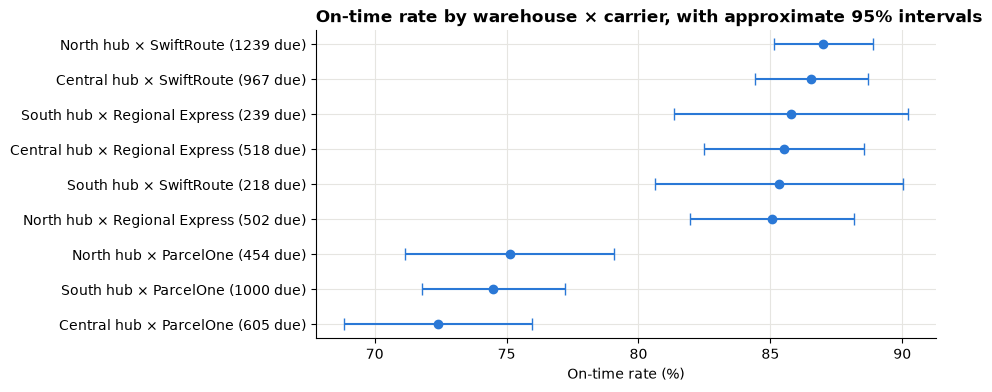

In [22]:
wc_ci = wc.copy()
half_width = 1.96 * np.sqrt(wc_ci["on_time_rate"] * (1 - wc_ci["on_time_rate"]) / wc_ci["due"])
wc_ci["low"], wc_ci["high"] = wc_ci["on_time_rate"] - half_width, wc_ci["on_time_rate"] + half_width
wc_ci = wc_ci.sort_values("on_time_rate")

labels = [f"{w} × {c} ({n} due)" for (w, c), n in zip(wc_ci.index, wc_ci["due"])]
ax = plt.gca()
ax.errorbar(wc_ci["on_time_rate"] * 100, range(len(wc_ci)),
            xerr=[(wc_ci["on_time_rate"] - wc_ci["low"]) * 100, (wc_ci["high"] - wc_ci["on_time_rate"]) * 100],
            fmt="o", capsize=4)
ax.set_yticks(range(len(wc_ci)), labels)
ax.set_title("On-time rate by warehouse × carrier, with approximate 95% intervals")
ax.set_xlabel("On-time rate (%)")
plt.show()

Read the chart above. Groups with fewer due shipments have **wider** bars. Cells for the same carrier overlap across warehouses, while the gap between the weakest carrier and the others is larger than the bars. That is the pattern that justifies a carrier-focused investigation, rather than a warehouse one.

> **Check your understanding 7**
>
> A cell with 40 due shipments has an on-time rate 8 points below the rest. Would you put it at the top of your report? What would you do instead?

---

## Part 11: Worked case: the monthly trend and the December disruption

The manager "felt" December was terrible. We build the monthly on-time rate **by promised month** (the month the deadline fell in), correctly and with the delivered-only shortcut, and show the due volume underneath.

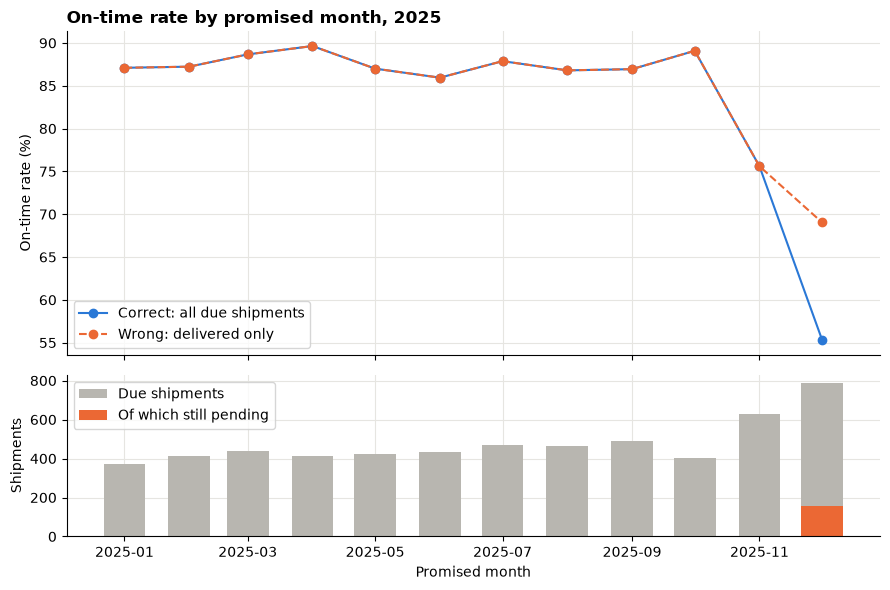

,due,on_time,pending,correct rate,delivered-only rate
promised_month,,,,,
2025-10,403,359,0,89.1%,89.1%
2025-11,627,474,0,75.6%,75.6%
2025-12,790,437,157,55.3%,69.0%


In [23]:
due = s[s["population"] == "due"].assign(promised_month=lambda d: d["promised_date"].dt.to_period("M"))

monthly = due.groupby("promised_month").agg(due=("on_time", "size"), on_time=("on_time", "sum"),
                                            pending=("pending", "sum"))
monthly["correct rate"] = monthly["on_time"] / monthly["due"]
delivered_m = due[due["delivered_date"].notna()].groupby("promised_month")["on_time"].agg(["sum", "size"])
monthly["delivered-only rate"] = delivered_m["sum"] / delivered_m["size"]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
x = monthly.index.to_timestamp()
ax1.plot(x, monthly["correct rate"] * 100, marker="o", label="Correct: all due shipments")
ax1.plot(x, monthly["delivered-only rate"] * 100, marker="o", linestyle="--", label="Wrong: delivered only")
ax1.set_title("On-time rate by promised month, 2025")
ax1.set_ylabel("On-time rate (%)")
ax1.legend(loc="lower left")
ax2.bar(x, monthly["due"], width=20, color="#b8b6b0", label="Due shipments")
ax2.bar(x, monthly["pending"], width=20, color="#eb6834", label="Of which still pending")
ax2.set_ylabel("Shipments")
ax2.set_xlabel("Promised month")
ax2.legend(loc="upper left")
fig.tight_layout()
plt.show()

monthly.tail(3).assign(**{c: monthly[c].tail(3).map("{:.1%}".format) for c in ["correct rate", "delivered-only rate"]})

Read the chart from top to bottom:

1. For most of the year the two lines are **identical**: by the cutoff, every shipment promised before December had been delivered, so the filter removed nothing.
2. In the last two months, **due volume rises** (the peak season) and the rate falls.
3. In **December** the lines split. Many December shipments are still pending at the cutoff; the delivered-only line drops them and reports a much milder decline than the correct line.

So the manager's feeling was right, and the delivered-only dashboard would have **understated** the disruption at exactly the moment it mattered. One honest caveat: December's correct rate is a **snapshot**. Some of those pending shipments will be delivered in January, all of them late, so the December rate cannot go up, but the lead-time picture for December is still incomplete.

The manager-ready summary:

In [24]:
dec = monthly.iloc[-1]
worst_carrier = by_carrier["on_time_rate"].idxmin()
print(
    f"As of 31 December 2025, {on_time_rate:.1%} of the {len(s[s['population'] == 'due'])} shipments due in 2025 "
    f"were delivered on time ({populations['not yet due']} not yet due and {populations['unknown promise']} "
    f"with no recorded promise are excluded). December was the worst month: {dec['correct rate']:.1%} of "
    f"{dec['due']:.0f} due shipments, with {dec['pending']:.0f} still pending; a delivered-only report would "
    f"have shown {dec['delivered-only rate']:.1%}. {worst_carrier} has the lowest on-time rate of the three "
    f"carriers ({by_carrier.loc[worst_carrier, 'on_time_rate']:.1%} of {by_carrier.loc[worst_carrier, 'due']} due) "
    f"and the largest overdue backlog ({by_carrier.loc[worst_carrier, 'pending']} pending)."
)

As of 31 December 2025, 81.9% of the 5742 shipments due in 2025 were delivered on time (99 not yet due and 12 with no recorded promise are excluded). December was the worst month: 55.3% of 790 due shipments, with 157 still pending; a delivered-only report would have shown 69.0%. ParcelOne has the lowest on-time rate of the three carriers (74.0% of 2059 due) and the largest overdue backlog (129 pending).


Before recommending "investigate the carrier", you would want evidence the data do not hold: whether the carrier serves harder routes or regions, when the warehouse actually handed parcels over (a late handover is the warehouse's delay, not the carrier's), whether the December peak exceeded agreed volumes, and whether the delivery scans are reliable. You list these in the lab's recommendation.

---

## Summary

| Question | Tool | Trap to avoid |
|---|---|---|
| What do I know at the snapshot? | Event dates, a cutoff, statuses checked against dates | Reading a blank delivery date as "never" |
| What is one row? | Shipment grain; orders can split | Counting orders for carrier service |
| Who is in the denominator? | Due population: promised on or before the cutoff, not canceled | Counting not-yet-due early deliveries; hiding unknown promises |
| How reliable is delivery? | On-time due ÷ **all** due shipments | Delivered-only filter (survivorship) |
| How long do deliveries take? | Completed-only lead time: median, percentiles, box plot, with the count | Quoting only the mean; pooling Express and Standard; forgetting the pending tail |
| How bad is the backlog? | Days past due, age bands, by carrier | Ignoring due-today pending shipments |
| Who performs worst? | Ratios of counts with due volumes; warehouse × carrier; mix-adjusted rates | Mean of percentages; blaming a warehouse for its carrier mix |
| Is a gap real? | Approximate 95% interval for each rate | Ranking small groups on noise |

---

## Quiz

Answer these at the start of the next lecture, which opens the **marketing case**: comparing campaigns. Write short answers.

1. A campaign had 10,000 visits, 800 add-to-carts and 200 purchases. What is the visit-to-purchase conversion rate? What is the cart-to-purchase rate?
2. Campaign A converted 2% of 1,000 visitors; campaign B converted 4% of 100 visitors. A colleague says the two campaigns together converted 3%. What is the right combined rate, and what rule from today does it use?
3. A campaign spent 5,000 currency units and brought 100 purchases worth 20,000 in revenue. What is the cost per acquisition (CPA)? What is the return on ad spend (ROAS)?
4. A customer saw a social media ad on Monday, searched for the brand on Thursday and bought. Under "last click" attribution, which channel gets the credit? What does that rule miss?
5. Campaign X has a higher conversion rate than campaign Y, but X was shown only to returning customers. Can you conclude that X's ads are better? What kind of evidence would let you say so?

---

## Lab briefing

In the **Lab** you:

1. Load the shipments, check keys, statuses and date order.
2. Build the due, not-yet-due and unknown-promise populations and reconcile them to the total.
3. Calculate the on-time rate overall and by month.
4. Compare carriers and warehouses with due counts, and a warehouse × carrier table.
5. Describe lead times by service with mean, median and 90th percentile.
6. List the oldest overdue pending shipments and compare shipments with orders.
7. Challenge: fix three broken dashboards, then recommend one process to investigate.

Open the [Session 11 lab](11_operations_service_lab.md).